In [2]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, plot_cdf, plot_pdf, set_style

# Apply standard style across all plots
set_style()

# Log-Normal Distribution: Modeling Multiplicative Growth, Latency & Wealth

## 1. Intuition & Motivation

In the Normal distribution, the Central Limit Theorem was driven by **addition**: the sum of many small independent random factors becomes Gaussian ($X = \sum \epsilon_i$).

What happens when a process grows **multiplicatively**?
$$Y = Y_0 \times (1 + r_1) \times (1 + r_2) \times \dots \times (1 + r_n)$$

Taking the natural logarithm transforms the product into a sum:
$$\ln(Y) = \ln(Y_0) + \sum_{i=1}^{n} \ln(1 + r_i)$$

By the Central Limit Theorem, the sum of log-shocks is **Normal**!
Therefore, the original variable $Y = e^{\ln(Y)}$ follows a **Log-Normal distribution**.

### Why It Matters:
Whenever a variable cannot be negative and changes by percentage amounts rather than fixed amounts, it is Log-Normal:
- **Finance**: Asset prices in the Black-Scholes model (Geometric Brownian Motion).
- **Computer Systems**: Web service request latency (p95, p99 tail times) and file sizes.
- **Economics**: Household income, wealth distributions, and company sizes (Gibrat's Law).
- **Geology & Biology**: Mineral concentration, particle sizes, and duration of viral incubation periods.

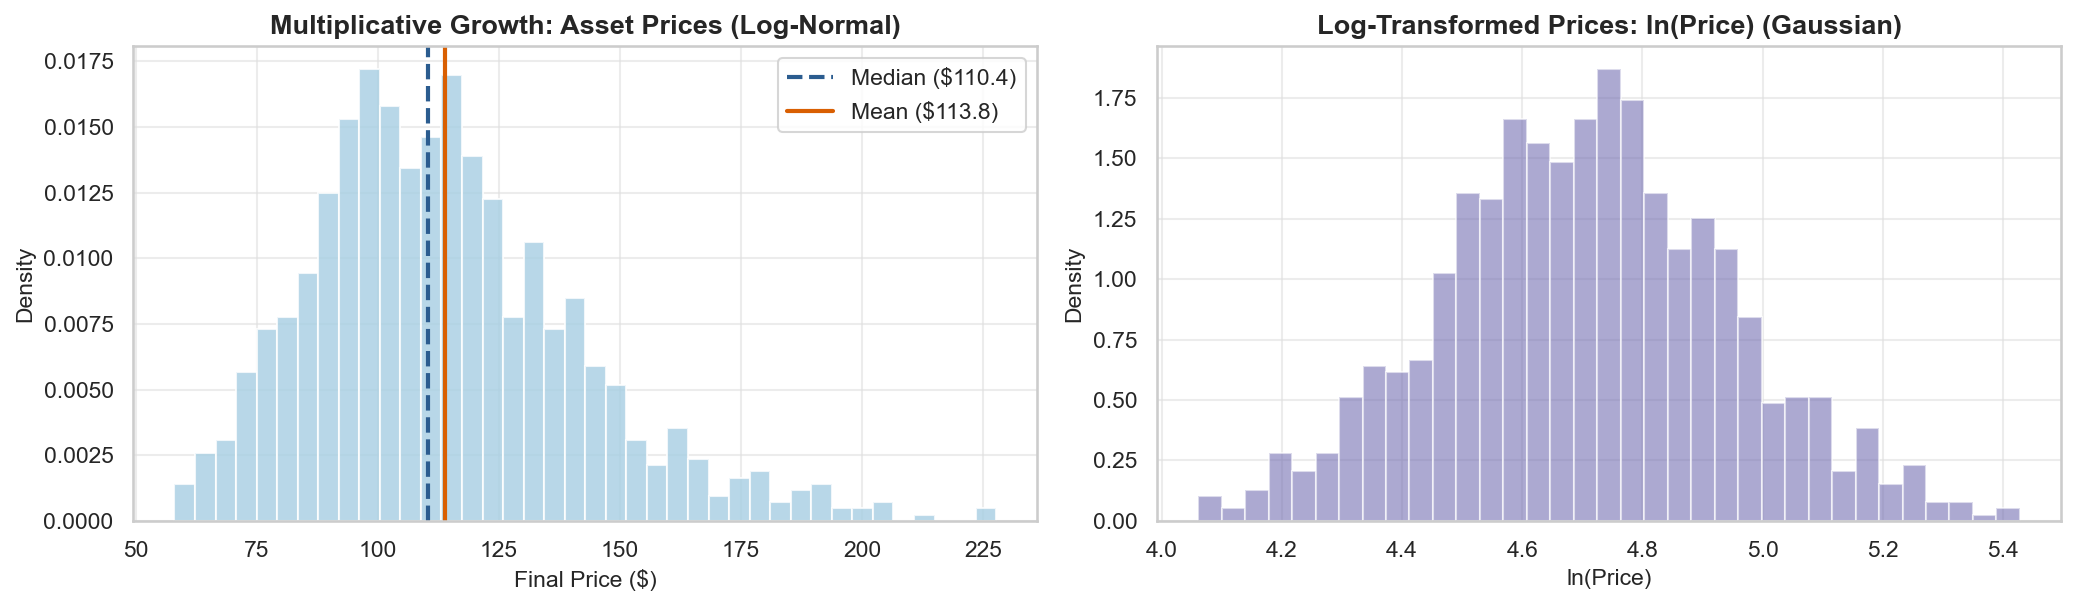

Asset Price Median: $110.36
Asset Price Mean:   $113.81 (Mean is pulled right by the heavy tail!)


In [3]:
# Multiplicative stock return simulation
n_assets = 1000
n_days = 252  # 1 trading year
initial_price = 100.0

# Seed for reproducibility
rng = np.random.default_rng(seed=42)

# Daily percentage shocks: mean return = 0.04% / day, daily volatility = 1.5%
daily_log_returns = rng.normal(loc=0.0004, scale=0.015, size=(n_assets, n_days))

# Cumulative compounding: S_T = S_0 * exp(sum(r_t))
total_log_returns = np.sum(daily_log_returns, axis=1)
final_prices = initial_price * np.exp(total_log_returns)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))

# Subplot 1: Compounded Asset Prices (Log-Normal, skewed)
ax1.hist(
    final_prices,
    bins=40,
    density=True,
    color=PALETTE["fill"],
    edgecolor="white",
    alpha=0.8,
)
ax1.axvline(
    np.median(final_prices),
    color=PALETTE["primary"],
    linestyle="--",
    linewidth=2,
    label=f"Median (${np.median(final_prices):.1f})",
)
ax1.axvline(
    np.mean(final_prices),
    color=PALETTE["secondary"],
    linestyle="-",
    linewidth=2,
    label=f"Mean (${np.mean(final_prices):.1f})",
)
ax1.set_title("Multiplicative Growth: Asset Prices (Log-Normal)", weight="bold")
ax1.set_xlabel("Final Price ($)")
ax1.set_ylabel("Density")
ax1.legend(frameon=True)

# Subplot 2: Log-Transformed Prices (Normal, symmetric)
ax2.hist(
    np.log(final_prices),
    bins=35,
    density=True,
    color=PALETTE["accent"],
    edgecolor="white",
    alpha=0.6,
)
ax2.set_title("Log-Transformed Prices: ln(Price) (Gaussian)", weight="bold")
ax2.set_xlabel("ln(Price)")
ax2.set_ylabel("Density")

plt.tight_layout()
plt.show()

print(f"Asset Price Median: ${np.median(final_prices):.2f}")
print(f"Asset Price Mean:   ${np.mean(final_prices):.2f} (Mean is pulled right by the heavy tail!)")

## 2. Mathematical Definition

A continuous random variable $Y$ follows a Log-Normal distribution, written:
$$Y \sim \text{LogNormal}(\mu, \sigma^2) \iff \ln(Y) \sim \mathcal{N}(\mu, \sigma^2)$$

### Parameters & Support
- **$\mu \in \mathbb{R}$ (log-mean)**: Mean of the underlying log-transformed variable $\ln(Y)$.
- **$\sigma > 0$ (log-std)**: Standard deviation of $\ln(Y)$ (governs the shape/skewness).
- **Support**: Strictly positive real numbers: $y \in (0, \infty)$.

> **Critical Warning:**
> $\mu$ and $\sigma$ are **NOT** the mean and standard deviation of $Y$ itself! They are the mean and standard deviation of its natural logarithm $\ln(Y)$.

### Probability Density Function (PDF)
By the change-of-variables formula ($f_Y(y) = f_X(\ln y) \cdot \left|\frac{d}{dy}\ln y\right| = f_X(\ln y) \cdot \frac{1}{y}$):
$$f(y) = \frac{1}{y \sigma \sqrt{2\pi}} \exp\left( -\frac{(\ln y - \mu)^2}{2\sigma^2} \right) \quad \text{for } y > 0$$

### Cumulative Distribution Function (CDF)
$$F(y) = P(Y \le y) = \Phi\left( \frac{\ln y - \mu}{\sigma} \right) = \frac{1}{2} \left[ 1 + \text{erf}\left( \frac{\ln y - \mu}{\sigma \sqrt{2}} \right) \right]$$

### SciPy Parameterization Convention
In `scipy.stats.lognorm(s, scale)`:
- `s = sigma` (the shape parameter)
- `scale = np.exp(mu)` (the scale parameter $m = e^\mu$, which equals the **median**!)
*(e.g., if $\mu = 0$ and $\sigma = 0.5$, use `s=0.5, scale=np.exp(0)=1.0`).*

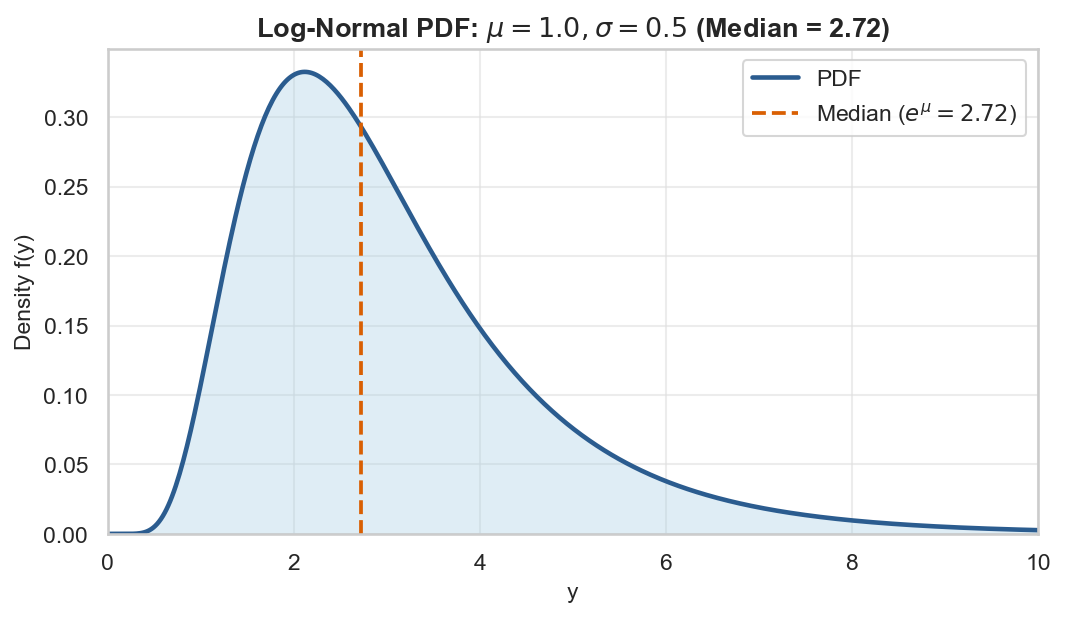

In [5]:
# Parameters: mu = 1.0, sigma = 0.5
mu_log = 1.0
sigma_log = 0.5
scale_param = np.exp(mu_log)  # e^1 ≈ 2.718 (median)

y_axis = np.linspace(0.01, 10.0, 500)
pdf_vals = stats.lognorm.pdf(y_axis, s=sigma_log, scale=scale_param)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_pdf(
    y_axis,
    pdf_vals,
    title=rf"Log-Normal PDF: $\mu={mu_log:.1f}, \sigma={sigma_log:.1f}$ (Median = {scale_param:.2f})",
    xlabel="y",
    ylabel="Density f(y)",
    fill=True,
    ax=ax,
)
ax.axvline(
    scale_param,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=1.8,
    label=rf"Median ($e^\mu = {scale_param:.2f}$)",
)
ax.legend(frameon=True)
ax.set_xlim(0, 10)
plt.show()

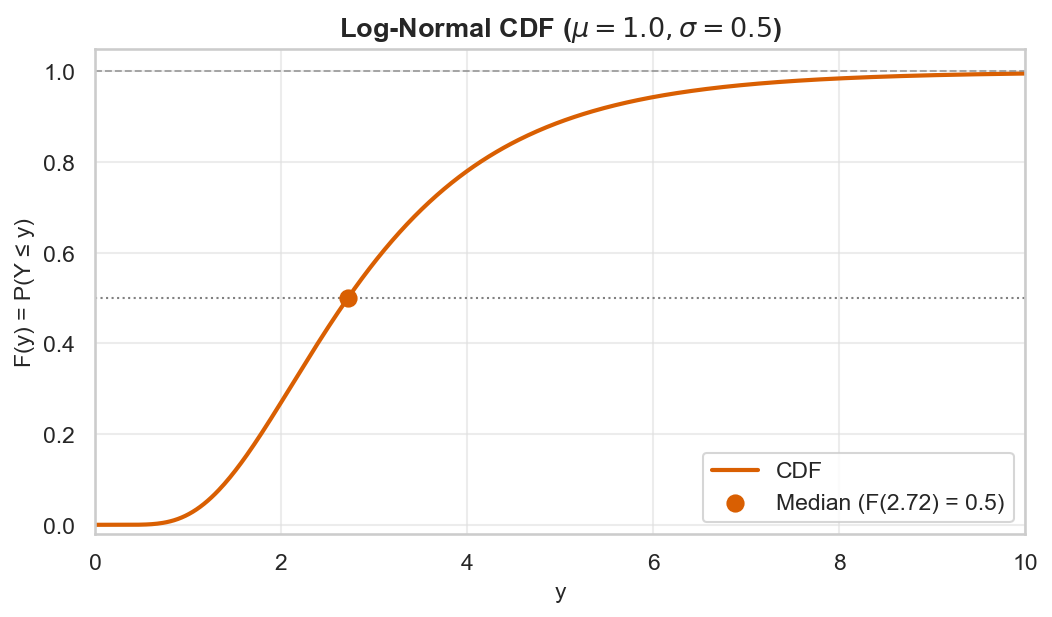

In [7]:
cdf_vals = stats.lognorm.cdf(y_axis, s=sigma_log, scale=scale_param)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_cdf(
    y_axis,
    cdf_vals,
    is_discrete=False,
    title=rf"Log-Normal CDF ($\mu={mu_log:.1f}, \sigma={sigma_log:.1f}$)",
    xlabel="y",
    ylabel="F(y) = P(Y ≤ y)",
    ax=ax,
)
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)
ax.scatter([scale_param], [0.5], color=PALETTE["secondary"], s=60, zorder=5, label=f"Median (F({scale_param:.2f}) = 0.5)")
ax.legend(frameon=True)
ax.set_xlim(0, 10)
plt.show()

## 3. Key Theoretical Properties

For $Y \sim \text{LogNormal}(\mu, \sigma^2)$:

### 1. The Inequality of Central Tendencies: $\text{Mode} < \text{Median} < \text{Mean}$
Because of positive skew, the three summary metrics diverge significantly:
- **Mode (Peak)**:
  $$\text{Mode} = e^{\mu - \sigma^2}$$
- **Median (50th Percentile)**:
  $$\text{Median} = e^{\mu}$$
- **Mean (Expected Value)**:
  $$\mathbb{E}[Y] = e^{\mu + \frac{\sigma^2}{2}}$$
*(Notice the ordering: $\text{Mode} < \text{Median} < \text{Mean}$. The mean is heavily elevated by the right tail!).*

### 2. Variance & Standard Deviation
$$\text{Var}(Y) = \left(e^{\sigma^2} - 1\right) e^{2\mu + \sigma^2} = (\mathbb{E}[Y])^2 \left(e^{\sigma^2} - 1\right)$$

### 3. Skewness ($\gamma_1$)
$$\gamma_1 = \left(e^{\sigma^2} + 2\right)\sqrt{e^{\sigma^2} - 1}$$
- Strictly positive ($\gamma_1 > 0$).
- Skewness depends **only on $\sigma$**, exploding exponentially as $\sigma$ increases.

### 4. Excess Kurtosis ($\gamma_2$)
$$\gamma_2 = e^{4\sigma^2} + 2e^{3\sigma^2} + 3e^{2\sigma^2} - 6$$

In [10]:
# Analytical moment calculations
mu_form = np.exp(mu_log + (sigma_log**2) / 2.0)
var_form = (np.exp(sigma_log**2) - 1.0) * np.exp(
    2 * mu_log + sigma_log**2
)
std_form = np.sqrt(var_form)
skew_form = (np.exp(sigma_log**2) + 2.0) * np.sqrt(np.exp(sigma_log**2) - 1.0)

# SciPy calculation
mu_sp, var_sp, skew_sp, kurt_sp = stats.lognorm.stats(
    s=sigma_log, scale=scale_param, moments="mvsk"
)

mode_form = np.exp(mu_log - sigma_log**2)
median_form = scale_param

print("--- LOG-NORMAL THEORETICAL MOMENTS ---")
print(f"Moment               | Analytical | SciPy")
print("-" * 46)
print(f"Mean                 | {mu_form:10.4f} | {float(mu_sp):10.4f}")
print(f"Variance             | {var_form:10.4f} | {float(var_sp):10.4f}")
print(f"Std Deviation        | {std_form:10.4f} | {np.sqrt(float(var_sp)):10.4f}")
print(f"Skewness (γ₁)        | {skew_form:10.4f} | {float(skew_sp):10.4f}")
print(f"Excess Kurtosis (γ₂) | {float(kurt_sp):10.4f} | {float(kurt_sp):10.4f}\n")
print(f"Mode:   {mode_form:.3f}")
print(f"Median: {median_form:.3f}")
print(f"Mean:   {mu_form:.3f}  --> Confirms Mode < Median < Mean!")

--- LOG-NORMAL THEORETICAL MOMENTS ---
Moment               | Analytical | SciPy
----------------------------------------------
Mean                 |     3.0802 |     3.0802
Variance             |     2.6948 |     2.6948
Std Deviation        |     1.6416 |     1.6416
Skewness (γ₁)        |     1.7502 |     1.7502
Excess Kurtosis (γ₂) |     5.8984 |     5.8984

Mode:   2.117
Median: 2.718
Mean:   3.080  --> Confirms Mode < Median < Mean!


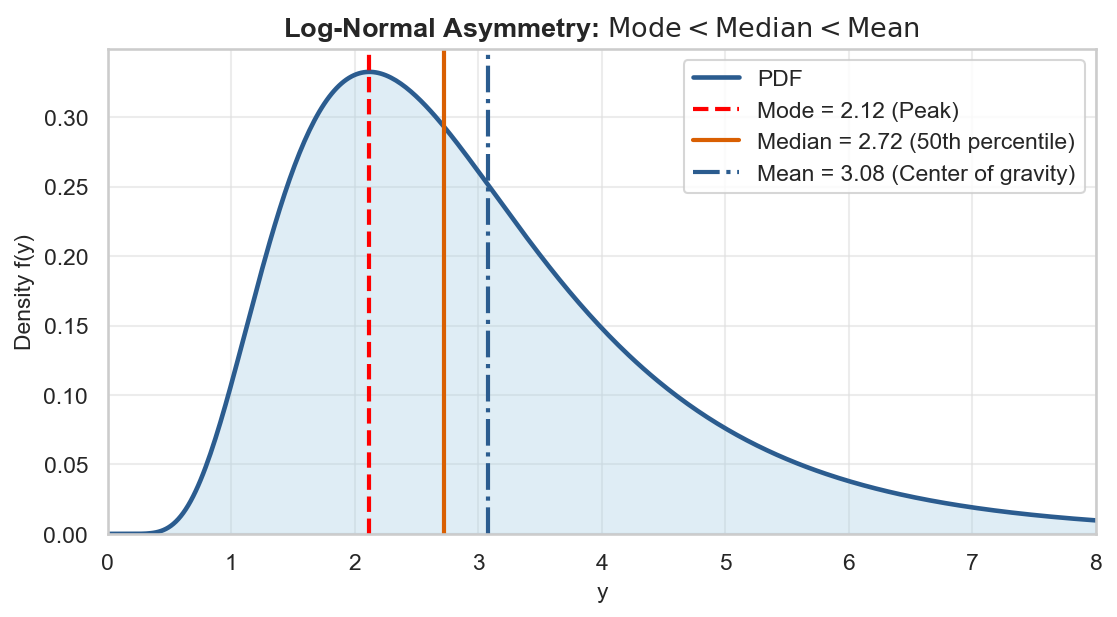

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
plot_pdf(
    y_axis,
    pdf_vals,
    title="Log-Normal Asymmetry: $\\text{Mode} < \\text{Median} < \\text{Mean}$",
    xlabel="y",
    ylabel="Density f(y)",
    fill=True,
    ax=ax,
)

# Overlay Mode, Median, Mean markers
ax.axvline(
    mode_form,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mode = {mode_form:.2f} (Peak)",
)
ax.axvline(
    median_form,
    color=PALETTE["secondary"],
    linestyle="-",
    linewidth=2,
    label=f"Median = {median_form:.2f} (50th percentile)",
)
ax.axvline(
    mu_form,
    color=PALETTE["primary"],
    linestyle="-.",
    linewidth=2,
    label=f"Mean = {mu_form:.2f} (Center of gravity)",
)

ax.set_xlim(0, 8)
ax.legend(frameon=True)
plt.show()

## 4. Parameter Variation

### 1. Effect of Shape Parameter $\sigma$ (Log-Volatility):
The shape parameter $\sigma$ dictates the skewness and tail fatness:
- **Small $\sigma$ (e.g., $\sigma = 0.25$)**: Low volatility; the distribution is narrow, bell-like, and nearly symmetric.
- **Moderate $\sigma$ (e.g., $\sigma = 0.5$ or $0.75$)**: Classic right-skewed profile with a distinct peak and pronounced tail.
- **Large $\sigma$ (e.g., $\sigma \ge 1.0$)**: Severe positive skew; peak collapses against zero, and the tail extends enormously.

### 2. Effect of Location Parameter $\mu$ (Log-Mean):
- Changing $\mu$ scales all values multiplicatively by $e^\mu$.
- The shape and relative skewness remain unchanged; the distribution simply expands or contracts along the horizontal axis.

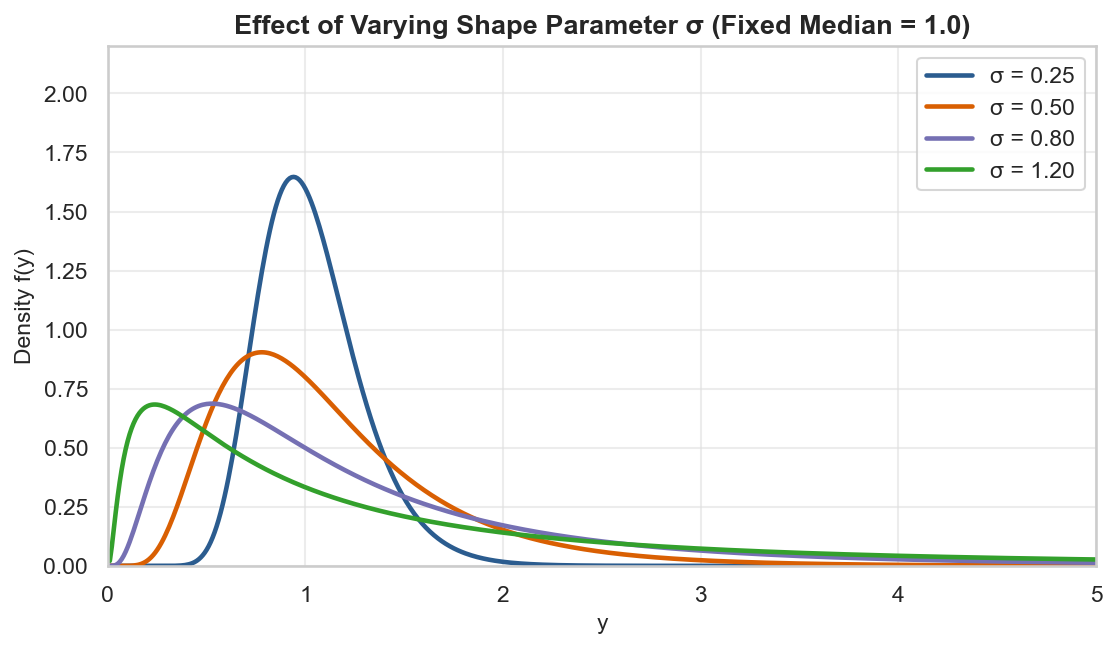

In [12]:
sigmas = [0.25, 0.5, 0.8, 1.2]
colors = [PALETTE["primary"], PALETTE["secondary"], PALETTE["accent"], "#33a02c"]
y_eval_sig = np.linspace(0.01, 5.0, 500)

fig, ax = plt.subplots(figsize=(8.5, 4.5))

for s_val, col in zip(sigmas, colors):
    pdf = stats.lognorm.pdf(y_eval_sig, s=s_val, scale=1.0)
    ax.plot(y_eval_sig, pdf, color=col, linewidth=2.2, label=f"σ = {s_val:.2f}")

ax.set_title("Effect of Varying Shape Parameter σ (Fixed Median = 1.0)", weight="bold")
ax.set_xlabel("y")
ax.set_ylabel("Density f(y)")
ax.set_ylim(0, 2.2)
ax.set_xlim(0, 5)
ax.legend(frameon=True)
plt.show()

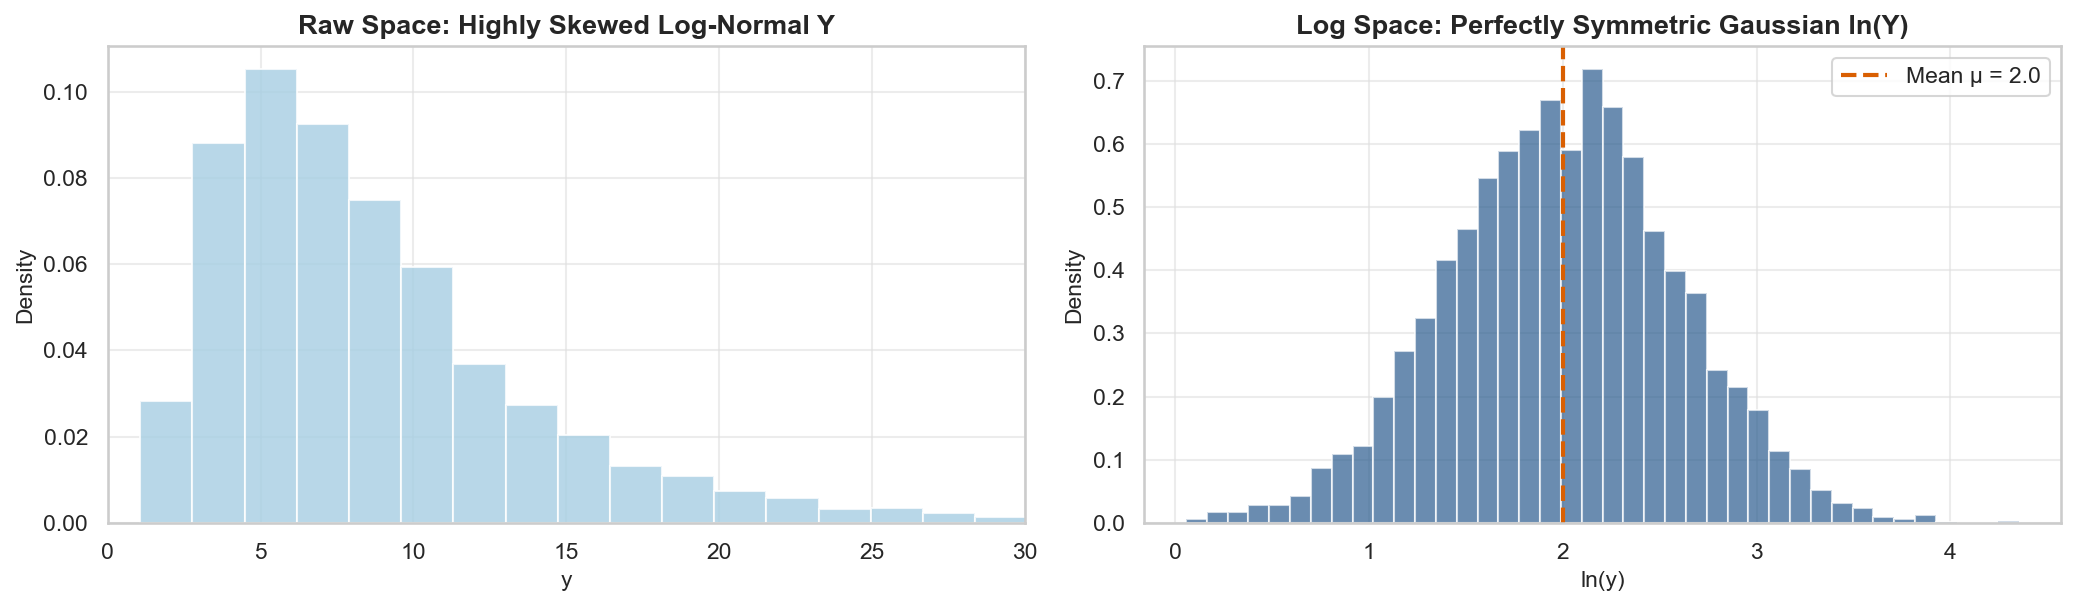

In [13]:
# Generate raw Log-Normal data
data_raw = stats.lognorm.rvs(s=0.6, scale=np.exp(2.0), size=5000, random_state=42)
data_logged = np.log(data_raw)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))

# Raw Space
ax1.hist(data_raw, bins=45, density=True, color=PALETTE["fill"], edgecolor="white", alpha=0.8)
ax1.set_title("Raw Space: Highly Skewed Log-Normal Y", weight="bold")
ax1.set_xlabel("y")
ax1.set_ylabel("Density")
ax1.set_xlim(0, 30)

# Log Space
ax2.hist(data_logged, bins=40, density=True, color=PALETTE["primary"], edgecolor="white", alpha=0.7)
ax2.axvline(2.0, color=PALETTE["secondary"], linestyle="--", linewidth=2, label="Mean μ = 2.0")
ax2.set_title("Log Space: Perfectly Symmetric Gaussian ln(Y)", weight="bold")
ax2.set_xlabel("ln(y)")
ax2.set_ylabel("Density")
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

## 5. Simulation & Law of Large Numbers

### Generating Log-Normal Variates:
To simulate $Y \sim \text{LogNormal}(\mu, \sigma^2)$:
1. Generate standard normal variates $Z \sim \mathcal{N}(0, 1)$.
2. Transform: $Y = \exp(\mu + \sigma Z)$.

By the **Law of Large Numbers**:
$$\bar{Y}_N = \frac{1}{N}\sum_{i=1}^N Y_i \xrightarrow{P} \mathbb{E}[Y] = e^{\mu + \frac{\sigma^2}{2}}$$

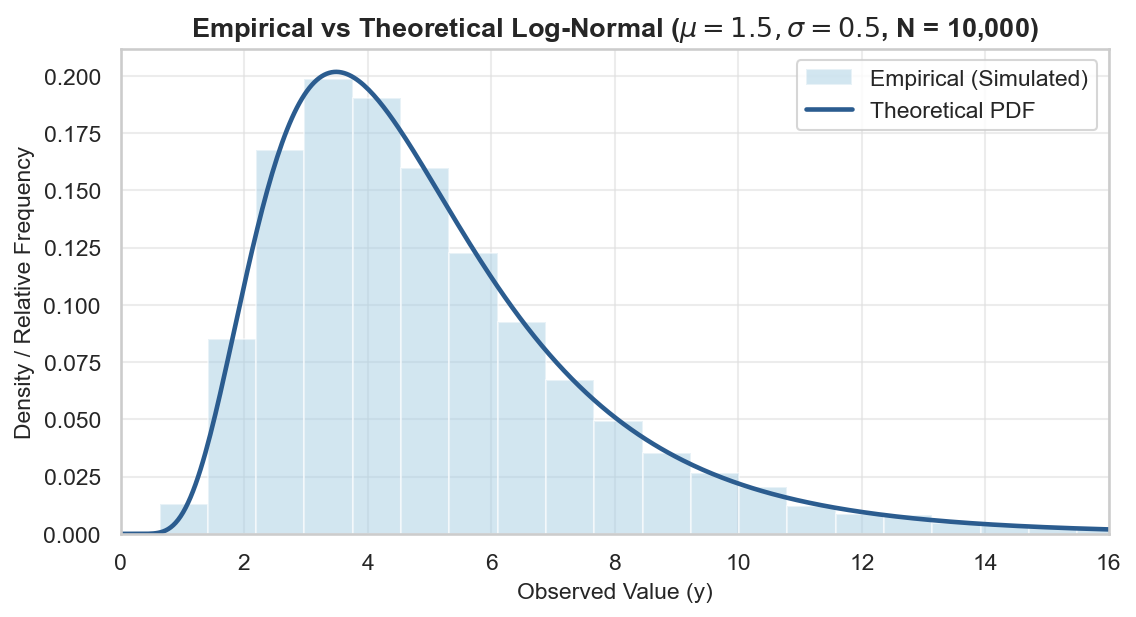

In [16]:
from utils.plotting import plot_sample_vs_theory

mu_sim = 1.5
sigma_sim = 0.5
scale_sim = np.exp(mu_sim)
sample_size = 10000

# Theoretical mean and variance
mu_target = np.exp(mu_sim + (sigma_sim**2) / 2.0)  # e^(1.625) ≈ 5.078
var_target = (np.exp(sigma_sim**2) - 1.0) * np.exp(2 * mu_sim + sigma_sim**2)

# Generate pseudo-random Log-Normal variates
samples_lognorm = stats.lognorm.rvs(
    s=sigma_sim, scale=scale_sim, size=sample_size, random_state=42
)

# Theoretical curve
y_th = np.linspace(0.01, 16.0, 400)
pdf_th = stats.lognorm.pdf(y_th, s=sigma_sim, scale=scale_sim)

# Plot empirical histogram vs continuous PDF
fig, ax = plt.subplots(figsize=(8.5, 4.2))
plot_sample_vs_theory(
    samples=samples_lognorm,
    x_theory=y_th,
    y_theory=pdf_th,
    is_discrete=False,
    title=rf"Empirical vs Theoretical Log-Normal ($\mu={mu_sim}, \sigma={sigma_sim}$, N = {sample_size:,})",
    xlabel="Observed Value (y)",
    ax=ax,
)
ax.set_xlim(0, 16)
plt.show()

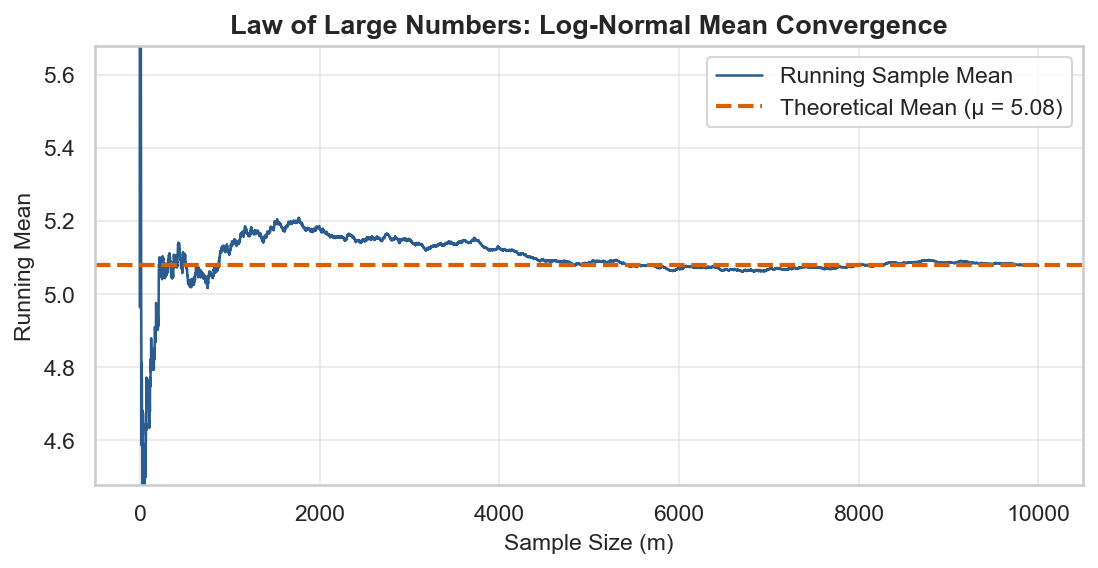

Sample Mean: 5.0779 (Theoretical: 5.0784)
Sample Var:  7.4157 (Theoretical: 7.3251)


In [18]:
# Running average convergence
running_ln_mean = np.cumsum(samples_lognorm) / np.arange(1, sample_size + 1)
plt.figure(figsize=(8.5, 3.8))
plt.plot(
    running_ln_mean,
    color=PALETTE["primary"],
    linewidth=1.2,
    label="Running Sample Mean",
)
plt.axhline(
    mu_target,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Mean (μ = {mu_target:.2f})",
)
plt.title("Law of Large Numbers: Log-Normal Mean Convergence")
plt.xlabel("Sample Size (m)")
plt.ylabel("Running Mean")
plt.ylim(mu_target - 0.6, mu_target + 0.6)
plt.legend(frameon=True)
plt.show()
print(f"Sample Mean: {np.mean(samples_lognorm):.4f} (Theoretical: {mu_target:.4f})")
print(f"Sample Var:  {np.var(samples_lognorm, ddof=1):.4f} (Theoretical: {var_target:.4f})")

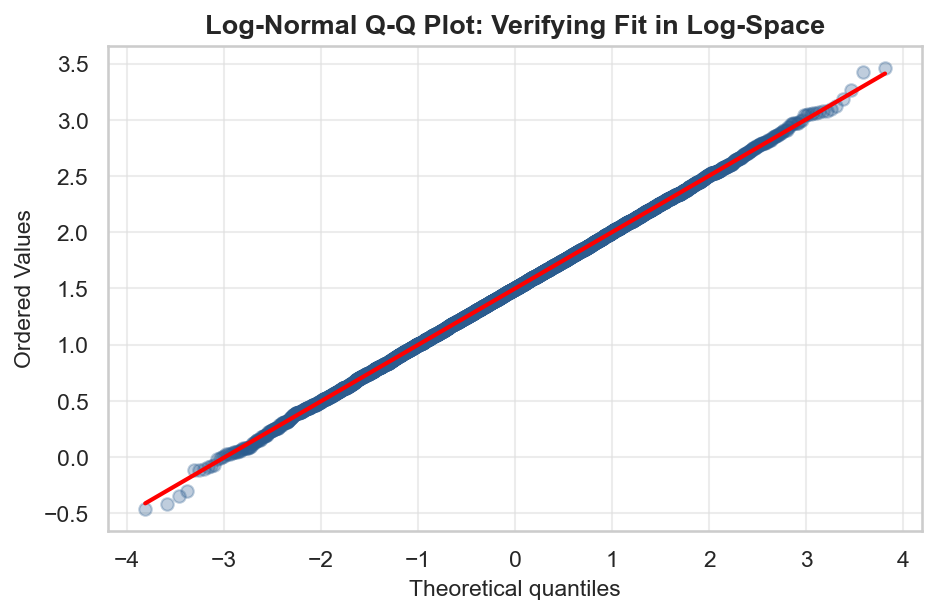

In [19]:
# Log-Normal Q-Q Plot Diagnostic (applied to log-transformed data)
fig, ax = plt.subplots(figsize=(7, 4.2))
stats.probplot(np.log(samples_lognorm), dist="norm", plot=ax)

# Style Q-Q plot
ax.get_lines()[0].set_markerfacecolor(PALETTE["primary"])
ax.get_lines()[0].set_color(PALETTE["primary"])
ax.get_lines()[0].set_alpha(0.3)
ax.get_lines()[1].set_color("red")
ax.get_lines()[1].set_linewidth(2)

ax.set_title("Log-Normal Q-Q Plot: Verifying Fit in Log-Space", weight="bold")
plt.show()

## 6. Applied Real-World Use Case: Web API Response Times & Tail Latency (p95 / p99)

### Scenario
Site Reliability Engineers (SREs) at a cloud platform monitor API response latency $Y$ (in milliseconds).
Because network routing, disk I/O, and garbage collection compound multiplicatively, latency follows a Log-Normal distribution:
$$Y \sim \text{LogNormal}(\mu = \ln(80) \approx 4.382, \, \sigma = 0.45)$$

### SRE Performance Metrics:
- **Typical User (p50 / Median)**:
  $$\text{p50} = e^\mu = e^{4.382} = \mathbf{80.0 \text{ ms}}$$
- **Worst 5% (p95 Tail)**: 95th percentile latency threshold.
- **Worst 1% (p99 Tail)**: 99th percentile tail threshold (the critical SLA benchmark).
- **Timeout Risk**: What percentage of requests exceed the client timeout threshold of $200$ ms ($P(Y > 200)$)?

In [20]:
mu_latency = np.log(80.0)  # ≈ 4.3820
sigma_latency = 0.45
scale_latency = np.exp(mu_latency)  # 80.0 ms

# Percentiles: p50 (median), p95, p99
p50 = stats.lognorm.ppf(0.50, s=sigma_latency, scale=scale_latency)
p90 = stats.lognorm.ppf(0.90, s=sigma_latency, scale=scale_latency)
p95 = stats.lognorm.ppf(0.95, s=sigma_latency, scale=scale_latency)
p99 = stats.lognorm.ppf(0.99, s=sigma_latency, scale=scale_latency)

# Timeout probability: P(Latency > 200 ms)
timeout_threshold = 200.0
prob_timeout = stats.lognorm.sf(
    timeout_threshold, s=sigma_latency, scale=scale_latency
)

# Mean latency
mean_latency = np.exp(mu_latency + (sigma_latency**2) / 2.0)

print("--- API LATENCY & SLA PERFORMANCE REPORT ---")
print(f"Mean Latency:        {mean_latency:.1f} ms")
print(f"p50 (Median SLA):    {p50:.1f} ms")
print(f"p90 SLA:             {p90:.1f} ms")
print(f"p95 SLA (Tail):      {p95:.1f} ms")
print(f"p99 SLA (Extreme):   {p99:.1f} ms\n")
print(f"Timeout Probability (> {timeout_threshold:.0f} ms): {prob_timeout * 100:.2f}% (approx 1 in {int(1/prob_timeout)} requests)")

--- API LATENCY & SLA PERFORMANCE REPORT ---
Mean Latency:        88.5 ms
p50 (Median SLA):    80.0 ms
p90 SLA:             142.4 ms
p95 SLA (Tail):      167.7 ms
p99 SLA (Extreme):   227.9 ms

Timeout Probability (> 200 ms): 2.09% (approx 1 in 47 requests)


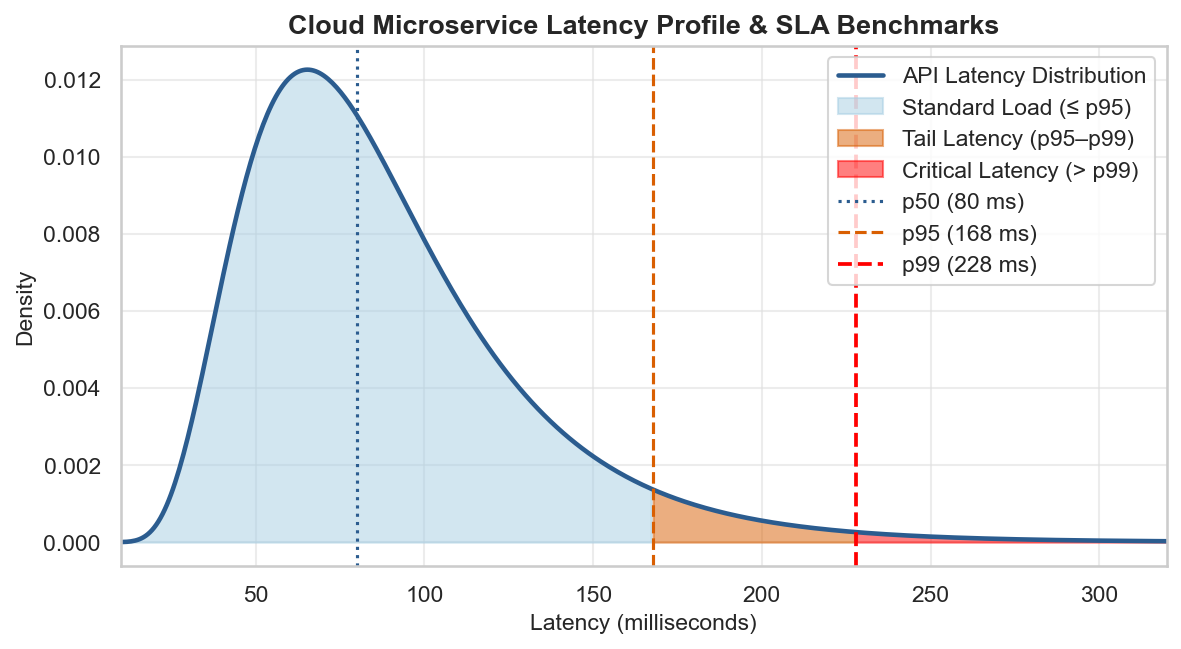

In [21]:
ms_axis = np.linspace(10, 320, 500)
pdf_latency = stats.lognorm.pdf(ms_axis, s=sigma_latency, scale=scale_latency)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(ms_axis, pdf_latency, color=PALETTE["primary"], linewidth=2.2, label="API Latency Distribution")

# Zone 1: Normal (<= p95)
mask_normal = ms_axis <= p95
ax.fill_between(ms_axis[mask_normal], pdf_latency[mask_normal], color=PALETTE["fill"], alpha=0.5, label="Standard Load (≤ p95)")

# Zone 2: Tail Latency (p95 to p99)
mask_tail = (ms_axis > p95) & (ms_axis <= p99)
ax.fill_between(ms_axis[mask_tail], pdf_latency[mask_tail], color=PALETTE["secondary"], alpha=0.5, label=f"Tail Latency (p95–p99)")

# Zone 3: Extreme Outliers (> p99)
mask_extreme = ms_axis > p99
ax.fill_between(ms_axis[mask_extreme], pdf_latency[mask_extreme], color="red", alpha=0.5, label=f"Critical Latency (> p99)")

# SLA markers
ax.axvline(p50, color=PALETTE["primary"], linestyle=":", linewidth=1.5, label=f"p50 ({p50:.0f} ms)")
ax.axvline(p95, color=PALETTE["secondary"], linestyle="--", linewidth=1.5, label=f"p95 ({p95:.0f} ms)")
ax.axvline(p99, color="red", linestyle="--", linewidth=1.8, label=f"p99 ({p99:.0f} ms)")

ax.set_title("Cloud Microservice Latency Profile & SLA Benchmarks", weight="bold")
ax.set_xlabel("Latency (milliseconds)")
ax.set_ylabel("Density")
ax.set_xlim(10, 320)
ax.legend(frameon=True, loc="upper right")
plt.show()

## 7. Parameter Estimation (Maximum Likelihood Estimation - MLE)

Given positive observations $y_1, y_2, \dots, y_N > 0$:

### The Log-Likelihood Function
$$\ln L(\mu, \sigma^2) = -\frac{N}{2}\ln(2\pi) - \frac{N}{2}\ln(\sigma^2) - \sum_{i=1}^{N}\ln(y_i) - \frac{1}{2\sigma^2}\sum_{i=1}^{N}(\ln y_i - \mu)^2$$

### The Elegant Solution:
Notice that $\ln(y_i)$ appears inside the exact same quadratic form as the standard Normal distribution!
Differentiating with respect to $\mu$ and $\sigma^2$ yields the **analytical MLEs**:
$$\hat{\mu}_{\text{MLE}} = \frac{1}{N}\sum_{i=1}^{N} \ln(y_i)$$
$$\hat{\sigma}^2_{\text{MLE}} = \frac{1}{N}\sum_{i=1}^{N} (\ln y_i - \hat{\mu})^2$$

*To find the MLE of a Log-Normal distribution, you simply take the natural logarithm of your data and compute the standard sample mean and variance!*

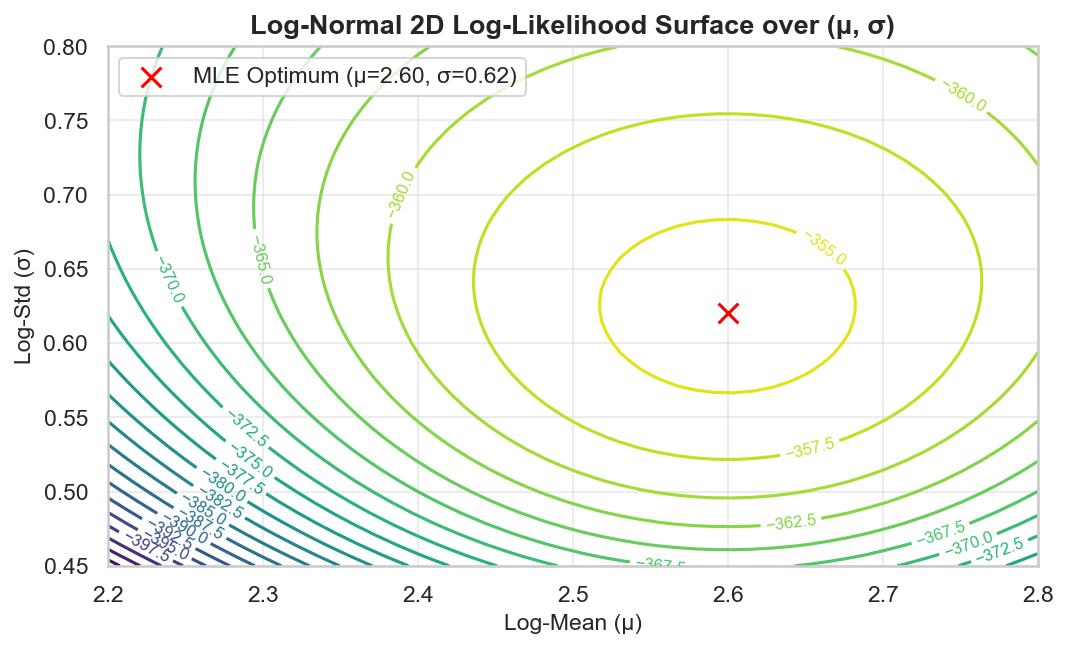

In [22]:
# True parameters
mu_true = 2.5
sigma_true = 0.60
N_obs = 100

# Generate synthetic observations
data_lognorm = stats.lognorm.rvs(
    s=sigma_true, scale=np.exp(mu_true), size=N_obs, random_state=101
)

# Analytical MLEs: mean and std of log-transformed data
log_data = np.log(data_lognorm)
mu_mle = np.mean(log_data)
sigma_mle = np.std(log_data, ddof=0)  # MLE divides by N

# 2D Grid search for visualization
m_cand = np.linspace(2.2, 2.8, 50)
s_cand = np.linspace(0.45, 0.80, 50)
M_grid, S_grid = np.meshgrid(m_cand, s_cand)


def lognorm_2d_log_lik(m_val, s_val, data):
    return np.sum(stats.lognorm.logpdf(data, s=s_val, scale=np.exp(m_val)))


log_lik_map = np.zeros_like(M_grid)
for i in range(M_grid.shape[0]):
    for j in range(M_grid.shape[1]):
        log_lik_map[i, j] = lognorm_2d_log_lik(
            M_grid[i, j], S_grid[i, j], data_lognorm
        )

plt.figure(figsize=(8, 4.5))
contours = plt.contour(
    M_grid, S_grid, log_lik_map, levels=25, cmap="viridis"
)
plt.clabel(contours, inline=True, fontsize=8)
plt.scatter(
    [mu_mle],
    [sigma_mle],
    color="red",
    s=90,
    zorder=5,
    marker="x",
    label=f"MLE Optimum (μ={mu_mle:.2f}, σ={sigma_mle:.2f})",
)

plt.title("Log-Normal 2D Log-Likelihood Surface over (μ, σ)", weight="bold")
plt.xlabel("Log-Mean (μ)")
plt.ylabel("Log-Std (σ)")
plt.legend(frameon=True)
plt.show()

In [23]:
from scipy.optimize import minimize


# Negative Log-Likelihood objective function
def neg_log_lik_ln(params, data):
    m_val, s_val = params
    if s_val <= 0.01:
        return 1e9
    return -np.sum(stats.lognorm.logpdf(data, s=s_val, scale=np.exp(m_val)))


res = minimize(
    neg_log_lik_ln, x0=[1.0, 1.0], args=(data_lognorm,), bounds=[(-10, 10), (0.01, 10)]
)
mu_num, sigma_num = res.x

# Standard errors
se_mu = sigma_mle / np.sqrt(N_obs)
se_sig = sigma_mle / np.sqrt(2 * N_obs)

print("--- LOG-NORMAL MLE ESTIMATION RESULTS ---")
print(f"Sample Size (N):            {N_obs}")
print(f"Parameter | True Value | Analytical MLE | Numerical MLE")
print("-" * 55)
print(f"μ         | {mu_true:10.4f} | {mu_mle:14.4f} | {mu_num:13.4f}")
print(f"σ         | {sigma_true:10.4f} | {sigma_mle:14.4f} | {sigma_num:13.4f}\n")
print(f"95% CI for μ: [{mu_mle - 1.96*se_mu:.4f}, {mu_mle + 1.96*se_mu:.4f}]")

--- LOG-NORMAL MLE ESTIMATION RESULTS ---
Sample Size (N):            100
Parameter | True Value | Analytical MLE | Numerical MLE
-------------------------------------------------------
μ         |     2.5000 |         2.5998 |        2.5998
σ         |     0.6000 |         0.6203 |        0.6203

95% CI for μ: [2.4782, 2.7214]


## 8. Related Distributions & Summary

The Log-Normal distribution is the primary bridge between additive and multiplicative processes:

1. **Normal Distribution ($X = \ln Y$)**:
   - If $Y \sim \text{LogNormal}(\mu, \sigma^2)$, then $\ln(Y) \sim \mathcal{N}(\mu, \sigma^2)$.
2. **Geometric Brownian Motion (GBM)**:
   - In continuous stochastic calculus, asset prices governed by $dS_t = \mu S_t dt + \sigma S_t dW_t$ result in log-normally distributed prices at any future time $T$:
     $$S_T \sim \text{LogNormal}\left(\ln(S_0) + (\mu - \frac{1}{2}\sigma^2)T, \, \sigma^2 T\right)$$
3. **Pareto Distribution (Power Laws)**:
   - For wealth and city populations, the Log-Normal model describes the majority (95%+), while the extreme top 1% often follows a **Pareto power-law distribution**.
4. **Gibrat's Law of Proportional Growth**:
   - If a company's proportional growth rate is independent of its current size, firm sizes over time converge to a Log-Normal distribution.

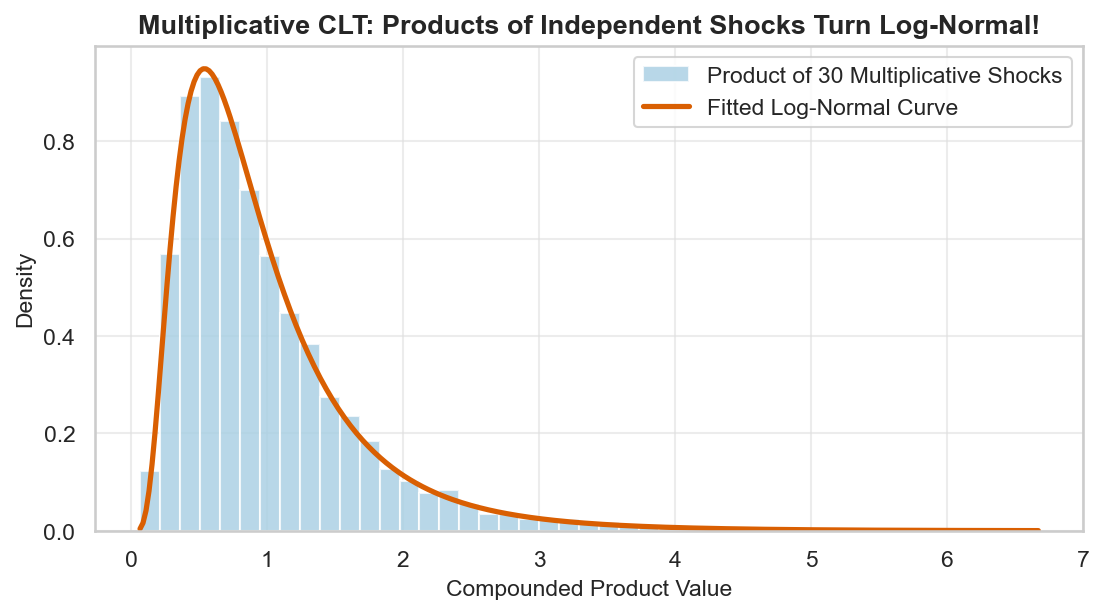

Product Mean: 0.989  |  Product Median: 0.809


In [24]:
# Demonstrating the Multiplicative Central Limit Theorem:
# Product of 30 independent Uniform(0.8, 1.2) growth factors
n_shocks = 30
n_trials_mult = 10000

# Draw independent positive multiplicative shocks
shocks = rng.uniform(0.8, 1.2, size=(n_trials_mult, n_shocks))

# Compute product across shocks for each trial
products = np.prod(shocks, axis=1)

# Fit log-normal to the product data
shape_fit, loc_fit, scale_fit = stats.lognorm.fit(products, floc=0)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x_mult_eval = np.linspace(min(products), max(products), 300)
pdf_fit = stats.lognorm.pdf(x_mult_eval, s=shape_fit, scale=scale_fit)

ax.hist(
    products,
    bins=45,
    density=True,
    color=PALETTE["fill"],
    edgecolor="white",
    alpha=0.8,
    label=f"Product of {n_shocks} Multiplicative Shocks",
)
ax.plot(
    x_mult_eval,
    pdf_fit,
    color=PALETTE["secondary"],
    linewidth=2.5,
    label="Fitted Log-Normal Curve",
)

ax.set_title("Multiplicative CLT: Products of Independent Shocks Turn Log-Normal!", weight="bold")
ax.set_xlabel("Compounded Product Value")
ax.set_ylabel("Density")
ax.legend(frameon=True)
plt.show()

print(f"Product Mean: {np.mean(products):.3f}  |  Product Median: {np.median(products):.3f}")

### Summary Card: Log-Normal Distribution

| Property | Formulation |
| :--- | :--- |
| **Notation** | $Y \sim \text{LogNormal}(\mu, \sigma^2)$ |
| **Parameters** | $\mu \in \mathbb{R}$ (mean of $\ln Y$), $\sigma > 0$ (std dev of $\ln Y$) |
| **Support** | $y \in (0, \infty)$ (Strictly positive) |
| **PDF** | $f(y) = \frac{1}{y \sigma \sqrt{2\pi}} \exp\left(-\frac{(\ln y - \mu)^2}{2\sigma^2}\right)$ |
| **CDF** | $F(y) = \Phi\left(\frac{\ln y - \mu}{\sigma}\right) = \frac{1}{2}\left[1 + \text{erf}\left(\frac{\ln y - \mu}{\sigma\sqrt{2}}\right)\right]$ |
| **Mode** | $e^{\mu - \sigma^2}$ |
| **Median** | $e^{\mu}$ (Scale parameter in SciPy) |
| **Mean ($\mathbb{E}[Y]$)** | $e^{\mu + \frac{\sigma^2}{2}}$ (Crucial: $\text{Mode} < \text{Median} < \text{Mean}$) |
| **Variance ($\text{Var}(Y)$)** | $(e^{\sigma^2} - 1) e^{2\mu + \sigma^2}$ |
| **Skewness ($\gamma_1$)** | $(e^{\sigma^2} + 2)\sqrt{e^{\sigma^2} - 1}$ (Strictly positive) |
| **MLE Estimators** | $\hat{\mu} = \frac{1}{N}\sum \ln(y_i)$, $\hat{\sigma}^2 = \frac{1}{N}\sum (\ln y_i - \hat{\mu})^2$ |
| **Key Use Cases** | Stock prices (Black-Scholes / GBM), API response latency (p95/p99), income and wealth, file sizes |